In [3]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [4]:
#per prima cosa collego il notebook di Jupyter a MongoDB dove sono salvati tutti i dati
from pymongo import MongoClient
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

client = MongoClient('mongodb://localhost:27017')

db = client['Football_Data']

collection_appearances = db['appearances']

documents = collection_appearances.find()

appearances_df = pd.DataFrame(list(documents))

appearances_df.head()

,_id,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,667a80a7d849a06a34c36576,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,667a80a7d849a06a34c36577,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,667a80a7d849a06a34c36578,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,667a80a7d849a06a34c36579,2234418_73333,2234418,73333,1274,6646,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,667a80a7d849a06a34c3657a,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90


In [5]:
#analizzando i primi 5 dati della collezione 'appearences', vediamo:
#_id è lidentificativo usato da MongoDB, quindi non utile per l'analisi
#appearance_id può essere usato come indice per la collezione
#game_id, player_id, player_club_id, player_current_club_id, competition_id sono i campi utili a noi per fare le join
#date, player_name, yellow_cards, red_cards, goals, assists, minutes_played sono i dati di questa collezione che possiamo analizzare

df = appearances_df.copy()
df

,_id,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,667a80a7d849a06a34c36576,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,667a80a7d849a06a34c36577,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,667a80a7d849a06a34c36578,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,667a80a7d849a06a34c36579,2234418_73333,2234418,73333,1274,6646,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,667a80a7d849a06a34c3657a,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1507346,667a8108d849a06a34da6588,4172154_659813,4172154,659813,15,15,2023-11-30,Piero Hincapié,EL,0,0,0,0,90
1507347,667a8108d849a06a34da6589,4172154_696027,4172154,696027,15,15,2023-11-30,Ayman Aourir,EL,0,0,0,0,2
1507348,667a8108d849a06a34da658a,4172154_7161,4172154,7161,15,15,2023-11-30,Jonas Hofmann,EL,0,0,0,0,10
1507349,667a8108d849a06a34da658b,4172154_743395,4172154,743395,15,15,2023-11-30,Noah Mbamba,EL,0,0,0,0,45


In [6]:
#Tramite la descrizione possiamo notare che il numero massimo di goal per giocatore per partita è elevato, ma dobbiamo fare più analisi a riguardo
#anche il numero massimo di minuti giocati per giocatore per partita è elevato essendo 120 min quando una partita dovrebbe durare 90 minuti con un
#eccesso di circa 10 min
df.describe()

,game_id,player_id,player_club_id,player_current_club_id,date,yellow_cards,red_cards,goals,assists,minutes_played
count,1.507351e+06,1.507351e+06,1.507351e+06,1.507351e+06,1507351,1.507351e+06,1.507351e+06,1.507351e+06,1.507351e+06,1.507351e+06
mean,3.014718e+06,1.798913e+05,2.881502e+03,3.638909e+03,2018-03-31 15:32:46.023572224,1.490230e-01,3.827244e-03,9.635778e-02,7.431050e-02,6.964984e+01
min,2.211607e+06,1.000000e+01,1.000000e+00,-1.000000e+00,2012-07-03 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,2.518634e+06,5.369600e+04,2.890000e+02,3.360000e+02,2015-04-19 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.200000e+01
50%,2.917390e+06,1.271420e+05,8.550000e+02,9.310000e+02,2018-02-24 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+01
75%,3.450701e+06,2.608060e+05,2.441000e+03,2.687000e+03,2021-02-27 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+01
max,4.227848e+06,1.186012e+06,8.367800e+04,8.367800e+04,2023-11-30 00:00:00,2.000000e+00,1.000000e+00,6.000000e+00,6.000000e+00,1.200000e+02
std,5.570794e+05,1.652259e+05,7.113885e+03,9.309395e+03,NaN,3.675721e-01,6.174624e-02,3.318755e-01,2.834195e-01,2.976078e+01


In [7]:
df.dtypes

_id                               object
appearance_id                     object
game_id                            int64
player_id                          int64
player_club_id                     int64
player_current_club_id             int64
date                      datetime64[ns]
player_name                       object
competition_id                    object
yellow_cards                       int64
red_cards                          int64
goals                              int64
assists                            int64
minutes_played                     int64
dtype: object

In [8]:
df = df.set_index('appearance_id')
df

,_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
appearance_id,,,,,,,,,,,,,
2231978_38004,667a80a7d849a06a34c36576,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
2233748_79232,667a80a7d849a06a34c36577,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2234413_42792,667a80a7d849a06a34c36578,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
2234418_73333,667a80a7d849a06a34c36579,2234418,73333,1274,6646,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
2234421_122011,667a80a7d849a06a34c3657a,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172154_659813,667a8108d849a06a34da6588,4172154,659813,15,15,2023-11-30,Piero Hincapié,EL,0,0,0,0,90
4172154_696027,667a8108d849a06a34da6589,4172154,696027,15,15,2023-11-30,Ayman Aourir,EL,0,0,0,0,2
4172154_7161,667a8108d849a06a34da658a,4172154,7161,15,15,2023-11-30,Jonas Hofmann,EL,0,0,0,0,10


In [9]:
#Come dati fondamentali di cui ho bisogno di avere dei valori non nulli considero i campi 'date' e 'player_name'

df = df[(~df['date'].isna()) & (~df['player_name'].isna())]
df

,_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
appearance_id,,,,,,,,,,,,,
2231978_38004,667a80a7d849a06a34c36576,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
2233748_79232,667a80a7d849a06a34c36577,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2234413_42792,667a80a7d849a06a34c36578,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
2234418_73333,667a80a7d849a06a34c36579,2234418,73333,1274,6646,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
2234421_122011,667a80a7d849a06a34c3657a,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4172154_659813,667a8108d849a06a34da6588,4172154,659813,15,15,2023-11-30,Piero Hincapié,EL,0,0,0,0,90
4172154_696027,667a8108d849a06a34da6589,4172154,696027,15,15,2023-11-30,Ayman Aourir,EL,0,0,0,0,2
4172154_7161,667a8108d849a06a34da658a,4172154,7161,15,15,2023-11-30,Jonas Hofmann,EL,0,0,0,0,10


In [10]:
#Adesso analizzo il numero di cartellini.
cards_df = df[(~df['yellow_cards'].isna()) & (~df['red_cards'].isna())]
cards_df.shape
#Non sono diminuiti i valori, quindi sicuramente non ci sono valori nulli tra i cartellini

(1507027, 13)

In [11]:
#Adesso analizzo il numero di goal e assist.
goal_df = df[(~df['goals'].isna()) & (~df['assists'].isna())]
goal_df.shape
#Non sono diminuiti i valori, quindi sicuramente non ci sono valori nulli tra i goal e gli assist.
#per analizzare i dati posso usare direttamente df.

(1507027, 13)

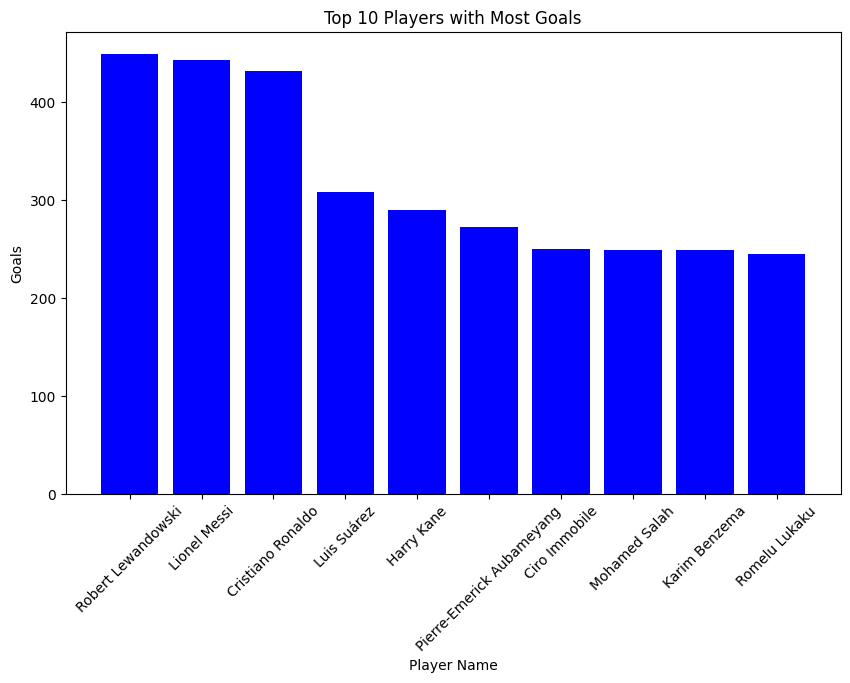

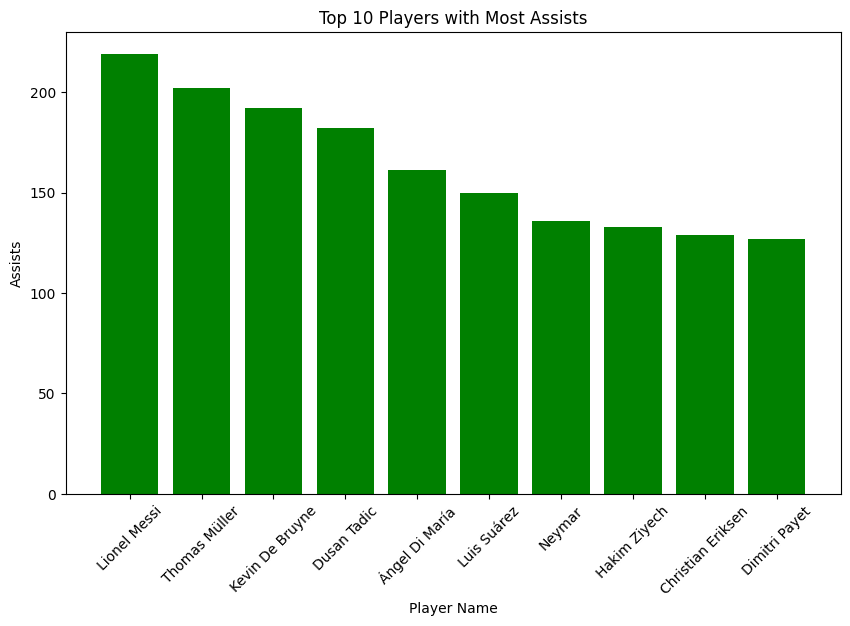

In [12]:
#analizzando i dati utilizzando degli istogrammi, ho dedotto il calciatore con più goal segnati e il giocatore con più assist effettuati
goals_df = df.groupby('player_name')['goals'].sum().reset_index()
assists_df = df.groupby('player_name')['assists'].sum().reset_index()

top_goals_df = goals_df.sort_values(by='goals', ascending=False).head(10)
top_assists_df = assists_df.sort_values(by='assists', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.bar(top_goals_df['player_name'], top_goals_df['goals'], color='blue')
plt.xlabel('Player Name')
plt.ylabel('Goals')
plt.title('Top 10 Players with Most Goals')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(top_assists_df['player_name'], top_assists_df['assists'], color='green')
plt.xlabel('Player Name')
plt.ylabel('Assists')
plt.title('Top 10 Players with Most Assists')
plt.xticks(rotation=45)
plt.show()

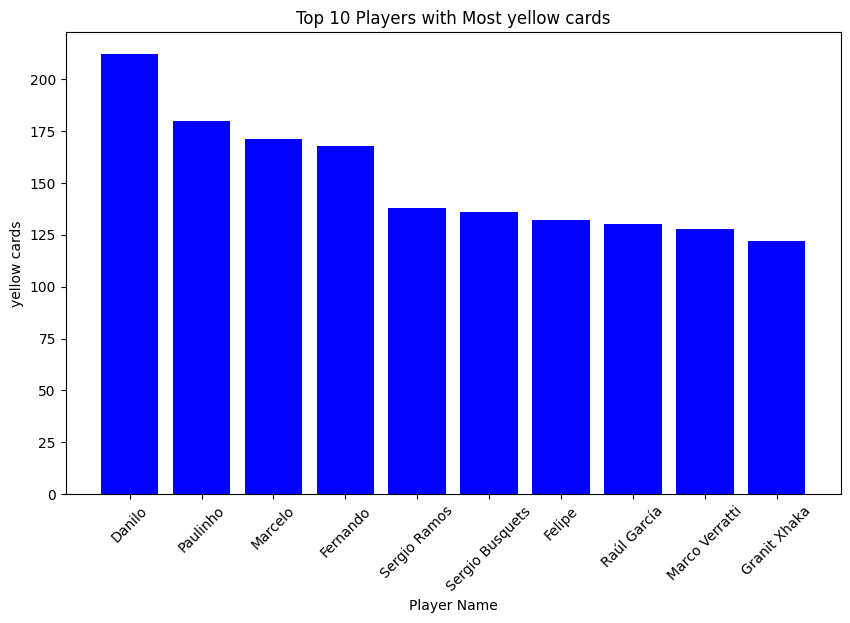

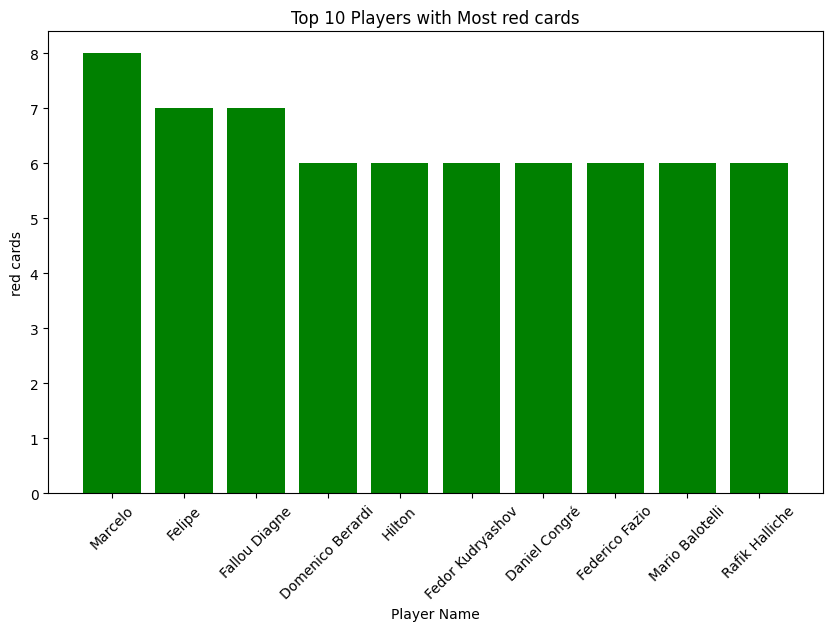

In [13]:
#analizzando i dati utilizzando degli istogrammi, ho dedotto il giocatore con più cartellini gialli e cartellini rossi. 
#potremmo analizzare le sotto-categorie dei ruoli dei giocatori per capire in quale ruolo si tende a fare più cartellini.

yc_df = df.groupby('player_name')['yellow_cards'].sum().reset_index()
rc_df = df.groupby('player_name')['red_cards'].sum().reset_index()

top_yc_df = yc_df.sort_values(by='yellow_cards', ascending=False).head(10)
top_rc_df = rc_df.sort_values(by='red_cards', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.bar(top_yc_df['player_name'], top_yc_df['yellow_cards'], color='blue')
plt.xlabel('Player Name')
plt.ylabel('yellow cards')
plt.title('Top 10 Players with Most yellow cards')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(top_rc_df['player_name'], top_rc_df['red_cards'], color='green')
plt.xlabel('Player Name')
plt.ylabel('red cards')
plt.title('Top 10 Players with Most red cards')
plt.xticks(rotation=45)
plt.show()

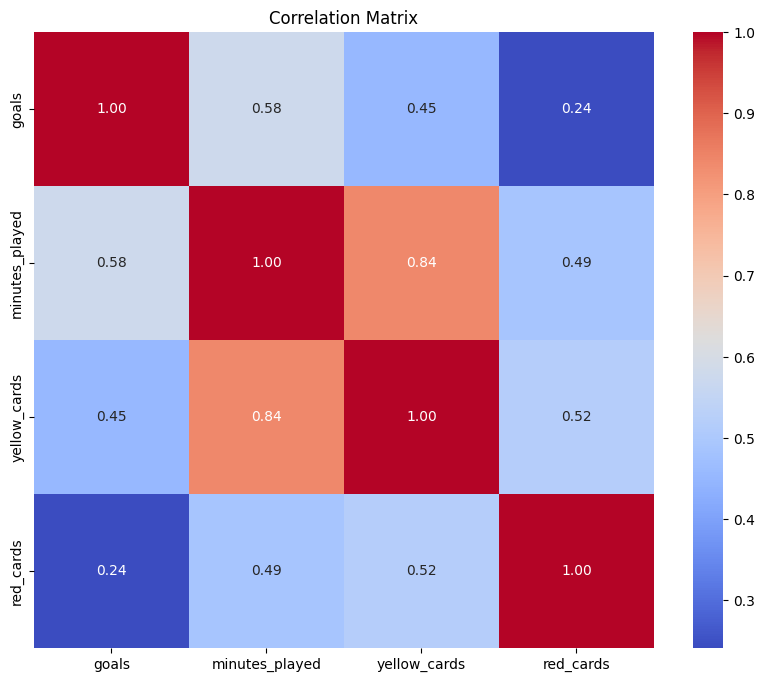

In [14]:
#Analizzo i dati goal, minuti giocati, e cartellini, raggruppati per giocatore, per vedere quanto sono in relazione tra di loro.
#Dalla mia analisi osservo che:
#tutti i dati hanno una correlazione direttamente proporzionale.
#goal-minuti giocati: sono fortemente correlati, abbastanza ovvio poiché avendo più tempo ci sono più probabilità di fare goal.

#goal-cartellini gialli: c'è una buona correlazione tra di loro, valore più interessante. Potremmo analizzare la sotto-categoria degli attaccanti
#(coloro che fanno goal) per vedere se la correlazione aumenta

#goal-cartellini rossi: c'è una correlazione bassa, come per i cartellini gialli potremmo analizzare un sottogruppo
#----
#minuti giocati-cartellini gialli: c'è una correlazione molto alta, come per i goal può essere per il fatto che giocando più tempo si possano prendere
#più cartellini, si potrebbe fare un analisi su quale minuto si prendono più cartellini

#minuti giocati-cartellini rossi: c'è una correlazione alta, vale lo stesso discorso fatto per i cartellini gialli
#----
#cartellini gialli-cartellini rossi: la correlazione è tanto alta dovuta al fatto che dopo x cartellini gialli si prende un cartellino rosso

cm=df[['player_name', 'goals', 'minutes_played', 'yellow_cards', 'red_cards']]

grouped_df = cm.groupby('player_name').sum().reset_index()

# Calcolo la matrice di correlazione
correlation_matrix = grouped_df[['goals', 'minutes_played', 'yellow_cards', 'red_cards']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

In [15]:
#voglio analizzare il rapporto tra le competizioni, le squadre e i cartellini. Per fare questo
#pulisco i dati togliendo quelli con competition_id null, faccio una join con le competizioni e le squadre

cards_df = df[~df['competition_id'].isna()]

club_df=pd.read_csv('clubs.csv')[['club_id', 'name']]
competition_df=pd.read_csv('competitions.csv')[['competition_id', 'country_id', 'name', 'country_name']]

merged_df=pd.merge(cards_df, club_df, left_on='player_club_id', right_on='club_id')
merged_df = merged_df.rename(columns = {'name': 'club_name'})

merged_df=pd.merge(merged_df, competition_df, left_on='competition_id', right_on='competition_id')
merged_df = merged_df.rename(columns = {'name': 'competition_name'})

merged_df['country_name'] = merged_df['country_name'].fillna('europa')
merged_df

,_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played,club_id,club_name,country_id,competition_name,country_name
0,667a80a7d849a06a34c3657e,2235545,19409,317,200,2012-07-05,Willem Janssen,ELQ,0,0,0,0,45,317,Football Club Twente,-1,europa-league-qualifikation,europa
1,667a80a7d849a06a34c3657f,2235545,30003,317,317,2012-07-05,Wout Brama,ELQ,0,0,0,0,90,317,Football Club Twente,-1,europa-league-qualifikation,europa
2,667a80a7d849a06a34c36580,2235545,30667,317,317,2012-07-05,Robbert Schilder,ELQ,0,0,2,1,90,317,Football Club Twente,-1,europa-league-qualifikation,europa
3,667a80a7d849a06a34c36581,2235545,34129,317,1435,2012-07-05,Wesley Verhoek,ELQ,0,0,0,0,90,317,Football Club Twente,-1,europa-league-qualifikation,europa
4,667a80a7d849a06a34c36582,2235545,36139,317,36,2012-07-05,Dusan Tadic,ELQ,0,0,1,0,45,317,Football Club Twente,-1,europa-league-qualifikation,europa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1499754,667a8108d849a06a34da6588,4172154,659813,15,15,2023-11-30,Piero Hincapié,EL,0,0,0,0,90,15,Bayer 04 Leverkusen Fußball,-1,europa-league,europa
1499755,667a8108d849a06a34da6589,4172154,696027,15,15,2023-11-30,Ayman Aourir,EL,0,0,0,0,2,15,Bayer 04 Leverkusen Fußball,-1,europa-league,europa
1499756,667a8108d849a06a34da658a,4172154,7161,15,15,2023-11-30,Jonas Hofmann,EL,0,0,0,0,10,15,Bayer 04 Leverkusen Fußball,-1,europa-league,europa
1499757,667a8108d849a06a34da658b,4172154,743395,15,15,2023-11-30,Noah Mbamba,EL,0,0,0,0,45,15,Bayer 04 Leverkusen Fußball,-1,europa-league,europa


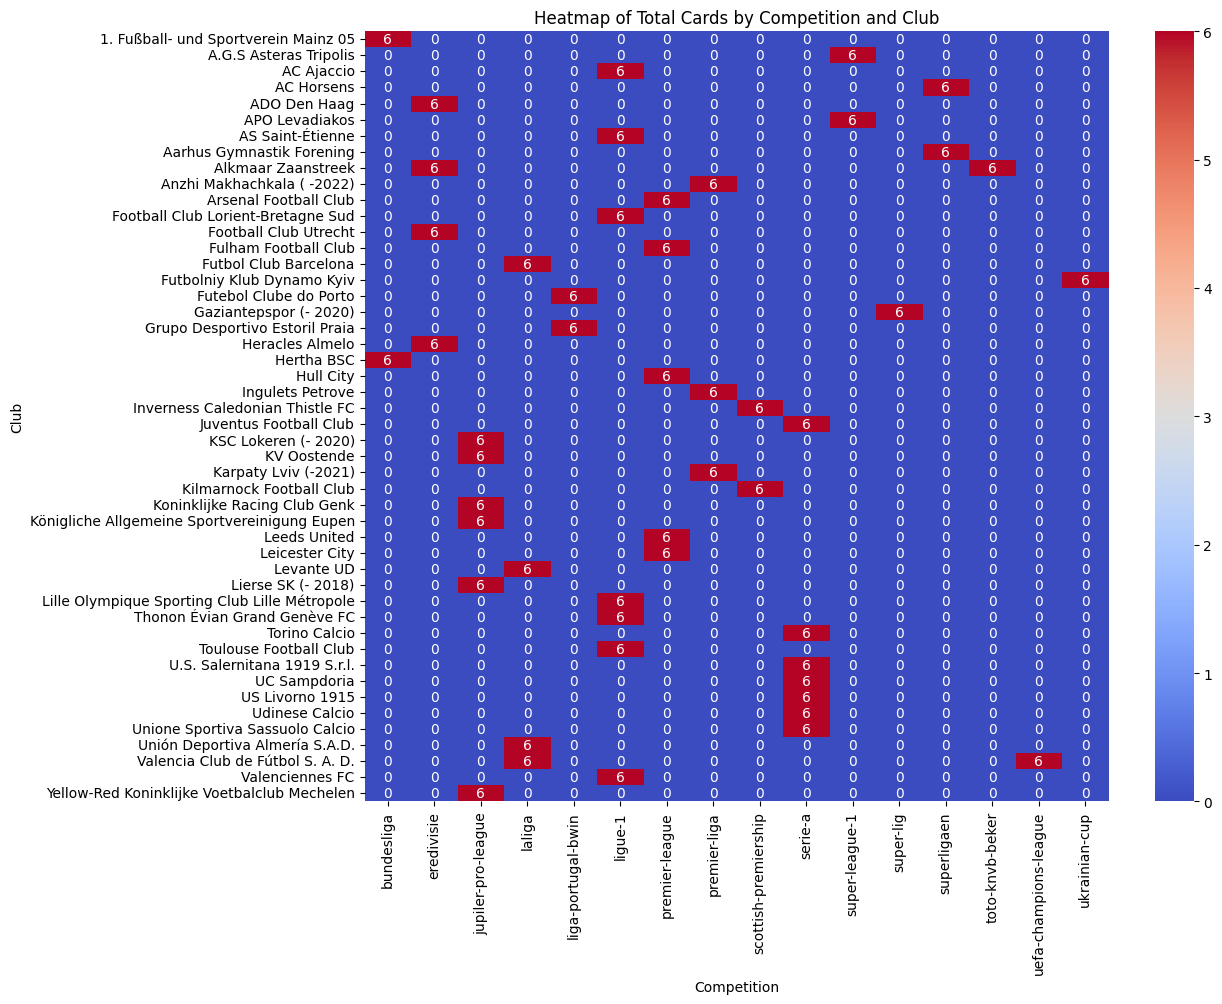

In [16]:
#ho provato ad analizzare quali sono le 50 squadre con più cartellini e in quale competizione li hanno presi. Essendo presenti
#troppe competizioni il grafico diventa banale per molti dati. Sarebbe meglio creare dei grafici su insiemi più piccoli di dati.

clubs_cards = merged_df[['yellow_cards', 'red_cards','club_name', 'competition_name']].drop_duplicates()
clubs_cards['total_cards'] = clubs_cards['yellow_cards'] + clubs_cards['red_cards']

clubs_cards= clubs_cards.groupby(['club_name', 'competition_name'])['total_cards'].sum().reset_index()
clubs_cards = clubs_cards.sort_values(by='total_cards', ascending=False).head(50)
pivot_df = clubs_cards.pivot(index='club_name', columns='competition_name', values='total_cards').fillna(0)

plt.figure(figsize=(12, 10))
sns.heatmap(pivot_df, annot=True, cmap='coolwarm', fmt='.0f')
plt.title('Heatmap of Total Cards by Competition and Club')
plt.xlabel('Competition')
plt.ylabel('Club')
plt.show()

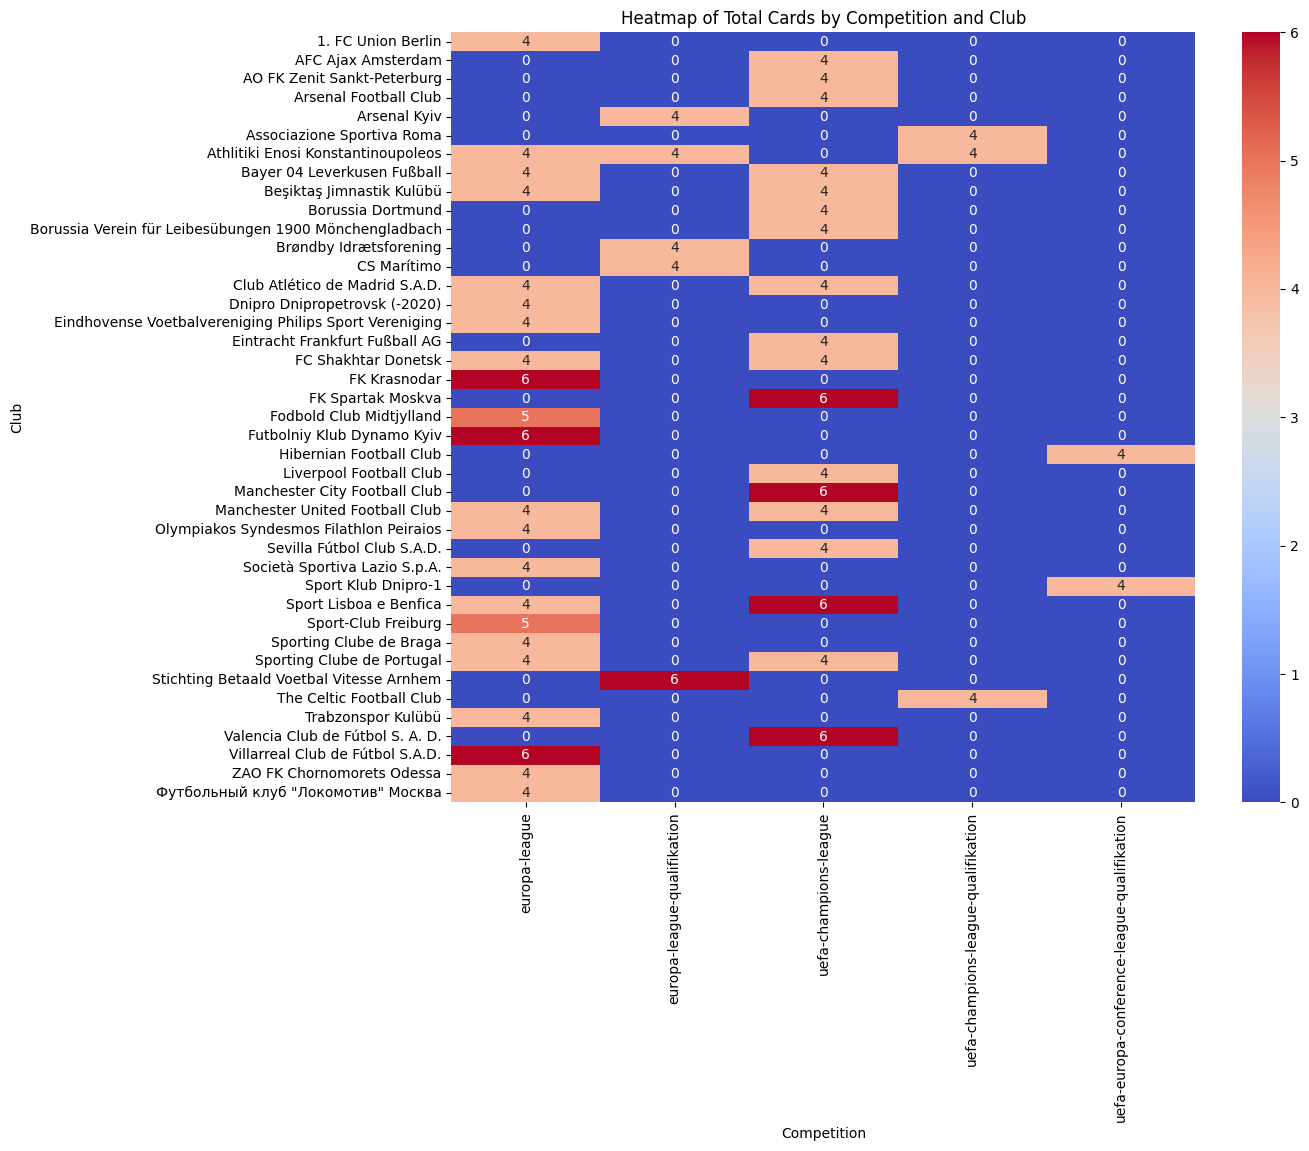

In [17]:
#Voglio allora analizzare il numero di cartellini totali all'interno dei campionati europei(considerando quelli internazionali)
#Ho notato tramite questa analisi che i club tendono a ricevere più cartellini gialli all'interno dei campionati rispetto alle qualificazioni

clubs_cards = merged_df[['yellow_cards', 'red_cards','club_name', 'competition_name', 'country_id']].drop_duplicates()
clubs_cards = clubs_cards[clubs_cards['country_id']==-1]

clubs_cards['total_cards'] = clubs_cards['yellow_cards'] + clubs_cards['red_cards']
clubs_cards= clubs_cards.groupby(['club_name', 'competition_name'])['total_cards'].sum().reset_index()
clubs_cards = clubs_cards.sort_values(by='total_cards', ascending=False).head(50)
pivot_df = clubs_cards.pivot(index='club_name', columns='competition_name', values='total_cards').fillna(0)

plt.figure(figsize=(12, 10))
sns.heatmap(pivot_df, annot=True, cmap='coolwarm', fmt='.0f')
plt.title('Heatmap of Total Cards by Competition and Club')
plt.xlabel('Competition')
plt.ylabel('Club')
plt.show()

In [19]:
#Adesso voglio analizzare il rapporto che potrebbe essere presente tra la posizione di una squadra e il numero di goal/cartellini
#importo dal db i dati dei club_games

collection_cGames = db['club_games']
documents_cGames = collection_cGames.find()

club_games_df = pd.DataFrame(list(documents_cGames))
club_games_df = club_games_df[['club_id', 'own_position']].dropna().drop_duplicates()

cards_goals = merged_df[['club_id', 'yellow_cards', 'red_cards', 'goals', 'assists']]
cards_goals = cards_goals.groupby(['club_id']).sum().reset_index()

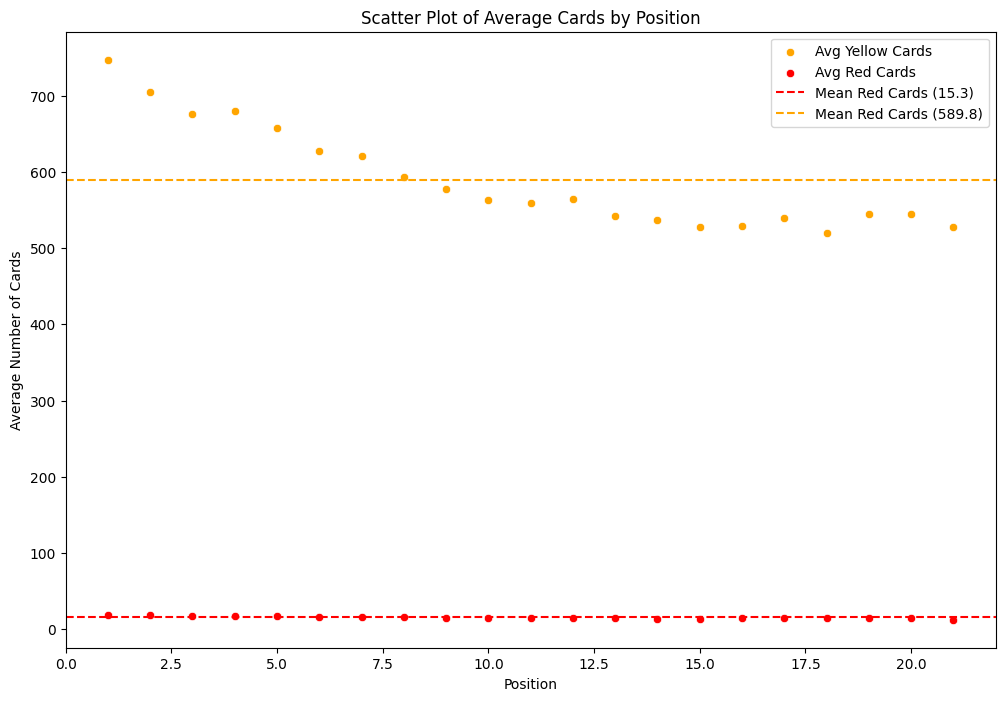

In [20]:
num_teams_per_position = club_games_df.groupby('own_position')['club_id'].nunique().reset_index()

cards_goals_grouped = cards_goals.groupby('club_id').sum().reset_index()

position_cards_goal = pd.merge(club_games_df, cards_goals_grouped, on='club_id', how='left')
position_cards_goal['own_position'] = pd.to_numeric(position_cards_goal['own_position'], errors='coerce')

position_cards_goal_agg = position_cards_goal.groupby('own_position')[['yellow_cards', 'red_cards']].sum().reset_index()
position_cards_goal_agg = pd.merge(position_cards_goal_agg, num_teams_per_position, on='own_position', how='left')

#consideriamo la media per non rappresentare la totalità dei cartellini ma solo la media in base alle posizioni
position_cards_goal_agg['avg_yellow_cards'] = position_cards_goal_agg['yellow_cards'] / position_cards_goal_agg['club_id']
position_cards_goal_agg['avg_red_cards'] = position_cards_goal_agg['red_cards'] / position_cards_goal_agg['club_id']

#rappresento una media dei cartellini per rendere più visualmente comprensibile
mean_red_cards = position_cards_goal_agg['avg_red_cards'].mean()
mean_yellow_cards = position_cards_goal_agg['avg_yellow_cards'].mean()

plt.figure(figsize=(12, 8))

sns.scatterplot(data=position_cards_goal_agg, x='own_position', y='avg_yellow_cards', color='orange', label='Avg Yellow Cards')
sns.scatterplot(data=position_cards_goal_agg, x='own_position', y='avg_red_cards', color='red', label='Avg Red Cards')

plt.axhline(y=mean_red_cards, color='red', linestyle='--', label=f'Mean Red Cards ({mean_red_cards:.1f})')
plt.axhline(y=mean_yellow_cards, color='orange', linestyle='--', label=f'Mean Red Cards ({mean_yellow_cards:.1f})')

plt.title('Scatter Plot of Average Cards by Position')
plt.xlabel('Position')
plt.ylabel('Average Number of Cards')
plt.legend()
plt.show()

#sulla base del grafico ottenuto posso dire che il numero di cartellini gialli aumenta salendo di posizione nella classifica,
#mentre per i cartellini rossi il numero di cartellini presi non va a variare troppo in base alla posizione

In [40]:
#voglio analizzare quali sono i club che investono di più sulle nuove leve. per fare questo ho bisogno della data di nascita dei
#giocatori(ricavata da players.csv), i nomi dei club(clubs.csv) e nel passare degli anni dove il giocatore ha giocato(appearances)
player_df = pd.read_csv('players.csv')

player_df.columns

Index(['player_id', 'first_name', 'last_name', 'name', 'last_season',
       'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'market_value_in_eur',
       'highest_market_value_in_eur', 'contract_expiration_date', 'agent_name',
       'image_url', 'url', 'current_club_domestic_competition_id',
       'current_club_name'],
      dtype='object')

In [51]:
from datetime import datetime

player_df = player_df[['player_id', 'date_of_birth']].dropna()
player_df['year'] = pd.to_datetime(player_df['date_of_birth']).dt.year
limit = 2024 - 20 #anno attuale meno il limite che vogliamo considerare

player_df = player_df[player_df['year']>=limit]
player_df = player_df.drop('date_of_birth', axis=1).drop_duplicates()
player_df

,player_id,year
1320,639580,2004
1330,656250,2004
1340,663890,2004
1346,668683,2004
1347,669633,2004
...,...,...
30288,1068053,2005
30289,923832,2005
30290,944355,2004
30291,1004618,2004


In [63]:
#ora faccio il merge tra i vari dati

clubs_young = df[['player_id', 'player_club_id', 'date']].copy()
clubs_young.loc[:, 'season_year'] = pd.to_datetime(clubs_young['date']).dt.year
clubs_young = clubs_young.drop('date', axis=1).drop_duplicates()

clubs_young = pd.merge(clubs_young, player_df, on='player_id', how='inner')
clubs_young = clubs_young.dropna()

clubs_young = clubs_young.rename(columns = {'player_club_id': 'club_id'})
clubs_young = pd.merge(clubs_young, club_df, on='club_id', how='inner').dropna()
clubs_young

,player_id,club_id,season_year,year,name
0,637669,3205,2019,2004,Kayserispor Kulübü
1,637669,3205,2020,2004,Kayserispor Kulübü
2,660979,2414,2020,2004,AC Horsens
3,743233,1083,2020,2004,FK Rostov
4,769063,237,2020,2004,Real Club Deportivo Mallorca S.A.D.
...,...,...,...,...,...
826,825441,520,2023,2005,Cercle Brugge Koninklijke Sportvereniging
827,708410,589,2023,2004,Antalyaspor
828,1111912,1421,2023,2004,Stade de Reims
829,700998,5,2023,2004,Associazione Calcio Milan


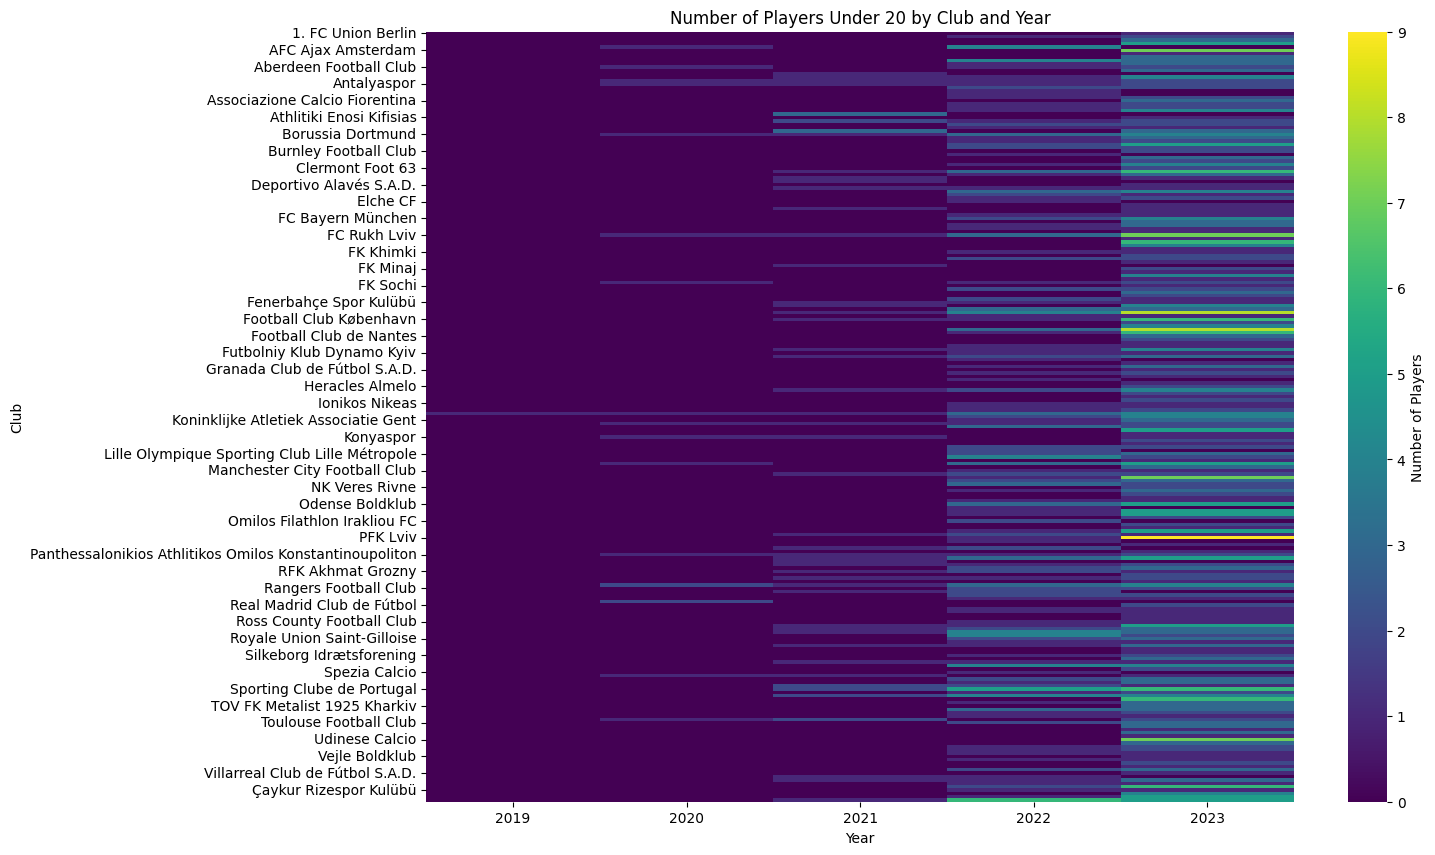

In [71]:
players_per_year_club = clubs_young.groupby(['season_year', 'name']).size().reset_index(name='num_players')

# Creazione della pivot table per preparare i dati per la heatmap
pivot_df = players_per_year_club.pivot(index='name', columns='season_year', values='num_players').fillna(0)

# Visualizzazione della heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(pivot_df, cmap='viridis', cbar_kws={'label': 'Number of Players'})
plt.title('Number of Players Under 20 by Club and Year')
plt.xlabel('Year')
plt.ylabel('Club')
plt.show()
#tramite questo schema posso analizzare quali sono i club che negli ultimi anni stanno investendo di più sui giovani, e abbiamo anche una gradazione
#per visualizzarne il numero.